# Maximize expected profit under a shared purchasing budget

An executed three-item example using the optional SciPy/HiGHS solver.
Install `pip install -e ".[solver]"`. Generate data, fit scenarios on history,
inspect an integer plan, evaluate held-out demand, and inspect financial and stock plots.
Both notebooks use identical data and compare both objectives.


In [1]:
from pathlib import Path
from dataclasses import replace, asdict
import math, random, statistics, sys, time
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from replenishment import (
    InventoryState, ConstantOrderPolicy, RiskObjective, SolverItemConfig, SolverOptions,
    SharedResourceLimits, DeterministicRollingHorizonPolicy, ScenarioRollingHorizonPolicy,
    plan_replenishment, simulate_coordinated_replenishment,
    generate_standard_simulation_rows, split_standard_simulation_rows,
    standard_simulation_rows_to_dataframe, build_article_configs_from_standard_rows,
    simulate_replenishment_for_articles, optimize_policy_candidates,
    build_replenishment_decisions_from_simulations, replenishment_decision_rows_to_dataframe,
    plot_replenishment_decisions,
)
plt.switch_backend("agg")
pd.set_option("display.max_columns", None)
PLOT_DIR = ROOT/"docs"/"plots"
PLOT_DIR.mkdir(exist_ok=True)
seed = 17
periods = 66
training_end = 42
H = 5
options = SolverOptions(time_limit=30, mip_rel_gap=0)


In [2]:
METHOD='profit_maximization'
TITLE='Maximize expected profit'
TARGET_NAME='Maximize profit'
COST_OBJECTIVE='total_cost'


## 1. Understand the objective

Revenue = selling price × fulfilled units.
Profit = revenue − procurement (all ordered units plus fixed charges) − holding.
For a fixed demand scenario, potential revenue is constant. Therefore minimizing
forgone revenue maximizes revenue; minimizing forgone revenue plus operating
costs maximizes profit. We use the **mean** objective, so this equivalence also
holds in expectation. CVaR of costs is not generally CVaR of negative profit.

Minimize `sum(selling_price * lost_units + procurement + holding)` with
`cost_objective="total_cost"`. The price is the shortage weight, not the unit margin:
purchase costs are already included. Subtracting margin instead would double-count costs.

The solver maximizes the supplied finite-horizon model, not guaranteed realized
results under unknown future demand. Start with this exact one-period comparison:


In [3]:
# A high-ticket item can have lower profit than a cheaper item.
tiny_items = {
    "High revenue":SolverItemConfig(1,1,stockout_cost_per_unit=20,order_cost_per_unit=19),
    "High margin":SolverItemConfig(1,1,stockout_cost_per_unit=12,order_cost_per_unit=3),
}
tiny_states = {uid:InventoryState(0,0,0,0) for uid in tiny_items}
tiny_records = []
for label,mode in [("Maximize revenue","lost_sales"),("Maximize profit","total_cost")]:
    plan = plan_replenishment(states=tiny_states,items=tiny_items,
        demand_scenarios={uid:[[1]] for uid in tiny_items},
        limits=SharedResourceLimits(procurement_budget=19),cost_objective=mode)
    sales = sum(tiny_items[uid].stockout_cost_per_unit*quantity for uid,quantity in plan.first_orders.items())
    expense = sum(tiny_items[uid].order_cost_per_unit*quantity for uid,quantity in plan.first_orders.items())
    # Exhaustive feasible orders independently verify this one-period optimum.
    choices = [(qa,qb) for qa in [0,1] for qb in [0,1] if 19*qa+3*qb<=19]
    scores = [20*qa+12*qb-(19*qa+3*qb if mode=="total_cost" else 0) for qa,qb in choices]
    achieved = sales-expense if mode=="total_cost" else sales
    assert achieved == max(scores)
    tiny_records.append(dict(objective=label,orders=dict(plan.first_orders),
        revenue=sales,procurement=expense,profit=sales-expense))
assert [r["revenue"] for r in tiny_records] == [20,12]
assert [r["profit"] for r in tiny_records] == [1,9]
display(pd.DataFrame(tiny_records))


,objective,orders,revenue,procurement,profit
0,Maximize revenue,"{'High revenue': 1, 'High margin': 0}",20.0,19.0,1.0
1,Maximize profit,"{'High revenue': 0, 'High margin': 1}",12.0,3.0,9.0


## 2. Generate and inspect the dataset

Three items have different selling prices, purchase costs and lead times. Item C
deliberately sells below purchase cost: revenue and profit objectives should
treat it differently. Initial stock and pipeline are zero, removing ambiguity
about sunk inventory cost. Currency is EUR; one period is one day.


In [4]:
rows = generate_standard_simulation_rows(n_unique_ids=3,periods=periods,
    start_date="2026-01-01",frequency_days=1,forecast_start_period=training_end,
    history_mean=3,history_std=1,forecast_mean=3,forecast_std=1,
    lead_time=1,initial_on_hand=0,current_stock=0,
    holding_cost_per_unit=.2,stockout_cost_per_unit=1,order_cost_per_order=.5,seed=seed)
item_info = pd.DataFrame([
    dict(unique_id="A",item="Expensive low-margin product",selling_price=20,purchase_cost=19,lead_time=2,cap=4),
    dict(unique_id="B",item="High-margin everyday product",selling_price=12,purchase_cost=3,lead_time=1,cap=12),
    dict(unique_id="C",item="Below-cost clearance product",selling_price=3,purchase_cost=4,lead_time=0,cap=8),
])
item_info["unit_margin_before_other_costs"] = item_info.selling_price-item_info.purchase_cost
item_parameters = item_info.set_index("unique_id").to_dict("index")
prices = item_info.set_index("unique_id").selling_price.to_dict()
date_to_period = {ds:k for k,ds in enumerate(sorted({r.ds for r in rows}))}
rng = random.Random(seed+421)
prepared = []
for row in rows:
    t = date_to_period[row.ds]
    if row.unique_id == "A":
        actual = max(0,round(rng.gauss(2,.8)))+int(t%7==5)
    elif row.unique_id == "B":
        actual = max(0,round(rng.gauss(4,1.4)))+int(t%7 in [4,5])
    else:
        actual = rng.choices([0,2,4],weights=[.2,.4,.4])[0]
    info = item_parameters[row.unique_id]
    prepared.append(replace(row,demand=actual,actuals=actual,lead_time=info["lead_time"],
        stockout_cost_per_unit=info["selling_price"]))
rows = prepared
backtest_rows,forecast_rows = split_standard_simulation_rows(rows)
def group_rows(values):
    return {uid:sorted([r for r in values if r.unique_id==uid],key=lambda r:r.ds)
            for uid in sorted({r.unique_id for r in values})}
train_by_article = group_rows(backtest_rows)
eval_by_article = group_rows(forecast_rows)
assert max(r.ds for r in backtest_rows)<min(r.ds for r in forecast_rows)
display(item_info)
display(standard_simulation_rows_to_dataframe(rows,library="pandas",include_demand=True).head(9))


,unique_id,item,selling_price,purchase_cost,lead_time,cap,unit_margin_before_other_costs
0,A,Expensive low-margin product,20,19,2,4,1
1,B,High-margin everyday product,12,3,1,12,9
2,C,Below-cost clearance product,3,4,0,8,-1


,unique_id,ds,demand,forecast,actuals,holding_cost_per_unit,stockout_cost_per_unit,order_cost_per_order,lead_time,initial_on_hand,current_stock,is_forecast,forecast_p50,forecast_p90
0,A,2026-01-01,2,1,2,0.2,20,0.5,2,0,0,False,1,1
1,A,2026-01-02,3,4,3,0.2,20,0.5,2,0,0,False,4,5
2,A,2026-01-03,3,3,3,0.2,20,0.5,2,0,0,False,3,4
3,A,2026-01-04,1,3,1,0.2,20,0.5,2,0,0,False,3,4
4,A,2026-01-05,2,4,2,0.2,20,0.5,2,0,0,False,4,5
5,A,2026-01-06,4,3,4,0.2,20,0.5,2,0,0,False,3,4
6,A,2026-01-07,2,2,2,0.2,20,0.5,2,0,0,False,2,2
7,A,2026-01-08,2,4,2,0.2,20,0.5,2,0,0,False,4,5
8,A,2026-01-09,2,0,2,0.2,20,0.5,2,0,0,False,0,0


## 3. Fit demand scenarios using history only

First 42 dates train weekly-phase forecasts; the remaining 24 are held out.
Six equal-weight joint residual paths use shared historical block indices.
Five future demand periods are planned at each decision, starting with t+1.
Shared limits are **EUR 35 purchasing per day**, 12 ordered units and 12 received
units per day, across all three items. Fixed charges consume purchasing budget.


In [5]:
# Six weeks of history fit calendar-phase demand means. Evaluation actuals are untouched.
phase_means = {uid:tuple(statistics.fmean([r.demand for r in series][phase::7])
    for phase in range(7)) for uid,series in train_by_article.items()}
def forecast_at(uid,absolute_period):
    return max(0,round(phase_means[uid][absolute_period%7]))
residuals = {uid:tuple(r.demand-forecast_at(uid,t) for t,r in enumerate(series))
             for uid,series in train_by_article.items()}
starts = random.Random(seed+22).sample(range(training_end-H+1),6)
def joint_scenarios(period):
    # Shared historical block starts preserve residual dependence across items.
    return {uid:tuple(tuple(max(0,forecast_at(uid,training_end+period+k+1)+residuals[uid][start+k])
        for k in range(H)) for start in starts) for uid in train_by_article}
def joint_provider(states):
    return joint_scenarios(next(iter(states.values())).period)
items = {uid:SolverItemConfig(lead_time=info["lead_time"],max_order_quantity=info["cap"],
    holding_cost_per_unit=.2,stockout_cost_per_unit=info["selling_price"],
    order_cost_per_order=.5,order_cost_per_unit=info["purchase_cost"])
    for uid,info in item_parameters.items()}
limits = SharedResourceLimits(procurement_budget=35,max_order_units=12,max_receiving_units=12)
objective = RiskObjective("mean")
rows = [replace(r,forecast=forecast_at(r.unique_id,date_to_period[r.ds]),
    forecast_percentiles={"p50":forecast_at(r.unique_id,date_to_period[r.ds])}) for r in rows]
backtest_rows,forecast_rows = split_standard_simulation_rows(rows)
eval_by_article = group_rows(forecast_rows)
df = standard_simulation_rows_to_dataframe(rows,library="pandas",include_demand=True)
assert df.actuals.eq(df.demand).all()
display(pd.DataFrame([dict(unique_id=uid,historical_demand_mean=statistics.fmean(r.demand for r in train_by_article[uid]),
    forecast_by_weekday=phase_means[uid],**asdict(item)) for uid,item in items.items()]))
print("Shared limits:",asdict(limits))


Shared limits: {'max_order_units': 12.0, 'procurement_budget': 35.0, 'max_receiving_units': 12.0}


,unique_id,historical_demand_mean,forecast_by_weekday,lead_time,max_order_quantity,holding_cost_per_unit,stockout_cost_per_unit,order_cost_per_order,order_cost_per_unit,review_period,min_order_quantity,pack_size
0,A,2.428571,"(2.1666666666666665, 2.3333333333333335, 2.0, ...",2,4,0.2,20.0,0.5,19.0,1,0,1
1,B,4.452381,"(4.333333333333333, 4.0, 4.333333333333333, 4....",1,12,0.2,12.0,0.5,3.0,1,0,1
2,C,2.000000,"(2.3333333333333335, 2.0, 2.6666666666666665, ...",0,8,0.2,3.0,0.5,4.0,1,0,1


## 4. Inspect the selected objective and financial plan

The item config retains actual procurement and holding costs in both methods.
Only `cost_objective` changes the terms being optimized. Current orders are
shared across scenarios; future orders may differ after observed histories diverge.
The table below reconciles every scenario's modeled loss to projected revenue/profit.


In [6]:
# Prices are the shortage weights; physical procurement costs remain real in BOTH runs.
probe_states = {uid:InventoryState(0,0,0,0) for uid in items}
probe_paths = joint_scenarios(0)
inspected_plan = plan_replenishment(states=probe_states,items=items,
    demand_scenarios=probe_paths,limits=limits,objective=objective,
    options=options,cost_objective=COST_OBJECTIVE)
plan_records = []
for scenario in range(len(starts)):
    potential = sum(prices[uid]*sum(probe_paths[uid][scenario]) for uid in items)
    revenue = sum(prices[uid]*(sum(probe_paths[uid][scenario])-sum(inspected_plan.lost_sales[uid][scenario]))
                  for uid in items)
    procurement = sum(sum((item.order_cost_per_order+q*item.order_cost_per_unit) if q else 0
        for q in inspected_plan.orders[uid][scenario]) for uid,item in items.items())
    holding = sum(item.holding_cost_per_unit*(sum(inspected_plan.inventories[uid][scenario])+
        (inspected_plan.orders[uid][scenario][0] if item.lead_time==0 else 0)) for uid,item in items.items())
    profit = revenue-procurement-holding
    target = revenue if COST_OBJECTIVE=="lost_sales" else profit
    assert abs((potential-inspected_plan.scenario_costs[scenario])-target)<1e-7
    plan_records.append(dict(scenario=scenario,potential_revenue=potential,
        projected_revenue=revenue,projected_procurement=procurement,projected_holding=holding,
        projected_profit=profit,model_loss=inspected_plan.scenario_costs[scenario]))
plan_df = pd.DataFrame(plan_records)
display(pd.DataFrame([dict(objective=COST_OBJECTIVE,status=inspected_plan.status,
    first_orders=dict(inspected_plan.first_orders),gap=inspected_plan.mip_gap,
    expected_model_loss=inspected_plan.mean_cost,solve_seconds=inspected_plan.solve_seconds,
    expected_target=plan_df.potential_revenue.mean()-inspected_plan.mean_cost)]))
display(plan_df.round(3))
display(pd.DataFrame([dict(unique_id=uid,scenario=s,planned_orders=orders,
    planned_lost_sales=inspected_plan.lost_sales[uid][s])
    for uid in items for s,orders in enumerate(inspected_plan.orders[uid])]).head(12))


,objective,status,first_orders,gap,expected_model_loss,solve_seconds,expected_target
0,total_cost,optimal,"{'A': 0, 'B': 7, 'C': 0}",0.0,331.133333,0.048844,205.7


,scenario,potential_revenue,projected_revenue,projected_procurement,projected_holding,projected_profit,model_loss
0,0,535,336,130.0,0.2,205.8,329.2
1,1,561,328,113.0,0.6,214.4,346.6
2,2,510,348,133.0,0.0,215.0,295.0
3,3,518,288,117.5,0.8,169.7,348.3
4,4,603,372,139.0,0.4,232.6,370.4
5,5,494,324,126.5,0.8,196.7,297.3


,unique_id,scenario,planned_orders,planned_lost_sales
0,A,0,"(0, 1, 1, 1, 0)","(3, 2, 0, 1, 2)"
1,A,1,"(0, 1, 0, 1, 0)","(1, 2, 1, 4, 2)"
2,A,2,"(0, 1, 1, 1, 0)","(1, 2, 0, 1, 2)"
3,A,3,"(0, 1, 1, 1, 0)","(3, 3, 0, 1, 3)"
4,A,4,"(0, 1, 1, 1, 0)","(3, 3, 1, 1, 1)"
5,A,5,"(0, 1, 1, 1, 0)","(2, 1, 0, 2, 2)"
6,B,0,"(7, 3, 5, 5, 3)","(0, 0, 0, 0, 0)"
7,B,1,"(7, 0, 7, 5, 5)","(0, 0, 0, 0, 0)"
8,B,2,"(7, 3, 5, 4, 5)","(0, 0, 0, 0, 0)"
9,B,3,"(7, 0, 3, 5, 4)","(0, 0, 0, 0, 0)"


## 5. Simulate both strategies on matched held-out demand

Replan after each observed demand; no future actual is supplied to the solver.
Demand, prices, initial conditions and shared limits are identical across methods.
Future prices and demand are exogenous; this example does not optimize prices.


In [7]:
strategies = {"Maximize revenue":"lost_sales","Maximize profit":"total_cost"}
runs = {}
started = time.perf_counter()
for name,mode in strategies.items():
    policies = {uid:ScenarioRollingHorizonPolicy(item,
        lambda state,uid=uid:joint_scenarios(state.period)[uid],horizon=H,
        objective=objective,options=options,cost_objective=mode) for uid,item in items.items()}
    configs = build_article_configs_from_standard_rows(forecast_rows,policies=policies)
    # Standard rows do not have a per-unit procurement field; supply it explicitly.
    configs = {uid:replace(config,order_cost_per_unit=items[uid].order_cost_per_unit)
               for uid,config in configs.items()}
    runs[name] = simulate_coordinated_replenishment(articles=configs,
        demand_scenarios=joint_provider,limits=limits,objective=objective,
        options=options,cost_objective=mode)
print(f"Two matched evaluations completed in {time.perf_counter()-started:.3f} seconds")
coordinated = runs[TARGET_NAME]
eval_simulations = coordinated.simulations
example_id = "A"


Two matched evaluations completed in 32.645 seconds


## 6. Financial results by strategy and item

Revenue is earned only on fulfilled units. Charge all placed orders, including
stock still on hand or in transit at the end. Forgone revenue is not subtracted
again as an expense. Assertions reconcile the financial ledger to simulations.


In [8]:
financial_records = []
for name,run in runs.items():
    for uid,result in run.simulations.items():
        item = items[uid]
        for snap in result.snapshots:
            fulfilled = snap.demand-snap.lost_sales
            revenue = prices[uid]*fulfilled
            purchase_cost = snap.order_placed*item.order_cost_per_unit
            fixed_cost = item.order_cost_per_order if snap.order_placed else 0
            holding_cost = snap.ending_on_hand*item.holding_cost_per_unit
            financial_records.append(dict(strategy=name,unique_id=uid,period=snap.period,
                demand=snap.demand,fulfilled=fulfilled,missed_units=snap.lost_sales,
                units_ordered=snap.order_placed,revenue=revenue,purchase_cost=purchase_cost,
                fixed_cost=fixed_cost,procurement_cost=purchase_cost+fixed_cost,
                holding_cost=holding_cost,profit=revenue-purchase_cost-fixed_cost-holding_cost))
financial_df = pd.DataFrame(financial_records)
financial_columns = ["demand","fulfilled","missed_units","units_ordered","revenue","purchase_cost",
                     "fixed_cost","procurement_cost","holding_cost","profit"]
summary_df = financial_df.groupby("strategy",as_index=False)[financial_columns].sum()
summary_df["fill_rate"] = summary_df.fulfilled/summary_df.demand
item_financial_df = financial_df.groupby(["strategy","unique_id"],as_index=False)[financial_columns].sum()
for name,run in runs.items():
    ledger = financial_df[financial_df.strategy==name]
    assert abs(ledger.procurement_cost.sum()-sum(r.summary.ordering_cost for r in run.simulations.values()))<1e-7
    assert abs(ledger.holding_cost.sum()-sum(r.summary.holding_cost for r in run.simulations.values()))<1e-7
    potential = sum(prices[uid]*r.summary.total_demand for uid,r in run.simulations.items())
    # The simulator's stockout cost is forgone revenue, not a second cash expense.
    assert abs(ledger.profit.sum()-(potential-sum(r.summary.total_cost for r in run.simulations.values())))<1e-7
    assert ledger.groupby("period").procurement_cost.sum().le(limits.procurement_budget+1e-9).all()
    assert ledger.groupby("period").units_ordered.sum().le(limits.max_order_units).all()
# The below-cost item starts empty and cannot generate positive profit by being ordered.
assert financial_df.query("strategy == 'Maximize profit' and unique_id == 'C'").units_ordered.sum()==0
display(summary_df.round(3))
display(item_financial_df.round(3))
display(financial_df[financial_df.strategy==TARGET_NAME].head(12))


,strategy,demand,fulfilled,missed_units,units_ordered,revenue,purchase_cost,fixed_cost,procurement_cost,holding_cost,profit,fill_rate
0,Maximize profit,205,111,94,121,1460,651.0,21.0,672.0,15.4,772.6,0.541
1,Maximize revenue,205,133,72,145,1594,807.0,27.5,834.5,24.8,734.7,0.649


,strategy,unique_id,demand,fulfilled,missed_units,units_ordered,revenue,purchase_cost,fixed_cost,procurement_cost,holding_cost,profit
0,Maximize profit,A,46,16,30,18,320,342.0,9.0,351.0,0.0,-31.0
1,Maximize profit,B,99,95,4,103,1140,309.0,12.0,321.0,15.4,803.6
2,Maximize profit,C,60,0,60,0,0,0.0,0.0,0.0,0.0,0.0
3,Maximize revenue,A,46,20,26,22,400,418.0,11.0,429.0,0.0,-29.0
4,Maximize revenue,B,99,95,4,103,1140,309.0,12.0,321.0,20.0,799.0
5,Maximize revenue,C,60,18,42,20,54,80.0,4.5,84.5,4.8,-35.3


,strategy,unique_id,period,demand,fulfilled,missed_units,units_ordered,revenue,purchase_cost,fixed_cost,procurement_cost,holding_cost,profit
72,Maximize profit,A,0,2,0,2,0,0,0.0,0.0,0.0,0.0,0.0
73,Maximize profit,A,1,2,0,2,1,0,19.0,0.5,19.5,0.0,-19.5
74,Maximize profit,A,2,1,0,1,1,0,19.0,0.5,19.5,0.0,-19.5
75,Maximize profit,A,3,1,1,0,1,20,19.0,0.5,19.5,0.0,0.5
76,Maximize profit,A,4,3,1,2,1,20,19.0,0.5,19.5,0.0,0.5
77,Maximize profit,A,5,2,1,1,1,20,19.0,0.5,19.5,0.0,0.5
78,Maximize profit,A,6,2,1,1,1,20,19.0,0.5,19.5,0.0,0.5
79,Maximize profit,A,7,2,1,1,1,20,19.0,0.5,19.5,0.0,0.5
80,Maximize profit,A,8,3,1,2,1,20,19.0,0.5,19.5,0.0,0.5
81,Maximize profit,A,9,2,1,1,0,20,0.0,0.0,0.0,0.0,20.0


## 7. Executed decisions and stock accounting


In [9]:
decision_rows=build_replenishment_decisions_from_simulations(forecast_rows,eval_simulations)
decision_df=replenishment_decision_rows_to_dataframe(decision_rows,library="pandas")
assert len(decision_df)==len(forecast_rows)
assert int(decision_df.missed_sales.sum())==sum(r.summary.total_lost_sales for r in eval_simulations.values())
for uid,result in eval_simulations.items():
    article_decisions=decision_df[decision_df.unique_id==uid].sort_values("ds")
    assert article_decisions.missed_sales.tolist()==[s.lost_sales for s in result.snapshots]
    assert article_decisions.ending_stock.tolist()==[s.ending_on_hand for s in result.snapshots]
    assert article_decisions.starting_stock.tolist()==[s.starting_on_hand for s in result.snapshots]
    assert article_decisions.demand.tolist()==[row.demand for row in eval_by_article[uid]]
columns=["unique_id","ds","demand","quantity","incoming_stock","starting_stock",
         "ending_stock","on_order","missed_sales","reorder_point","order_up_to"]
display(decision_df.loc[decision_df.unique_id==example_id,columns].head(16))


,unique_id,ds,demand,quantity,incoming_stock,starting_stock,ending_stock,on_order,missed_sales,reorder_point,order_up_to
0,A,2026-02-12,2,0,0,0,0,0,2,None,None
1,A,2026-02-13,2,1,0,0,0,1,2,None,None
2,A,2026-02-14,1,1,0,0,0,2,1,None,None
3,A,2026-02-15,1,1,1,1,0,2,0,None,None
4,A,2026-02-16,3,1,1,1,0,2,2,None,None
5,A,2026-02-17,2,1,1,1,0,2,1,None,None
6,A,2026-02-18,2,1,1,1,0,2,1,None,None
7,A,2026-02-19,2,1,1,1,0,2,1,None,None
8,A,2026-02-20,3,1,1,1,0,2,2,None,None
9,A,2026-02-21,2,0,1,1,0,1,1,None,None


## 8. Example items: demand, stock and missed sales


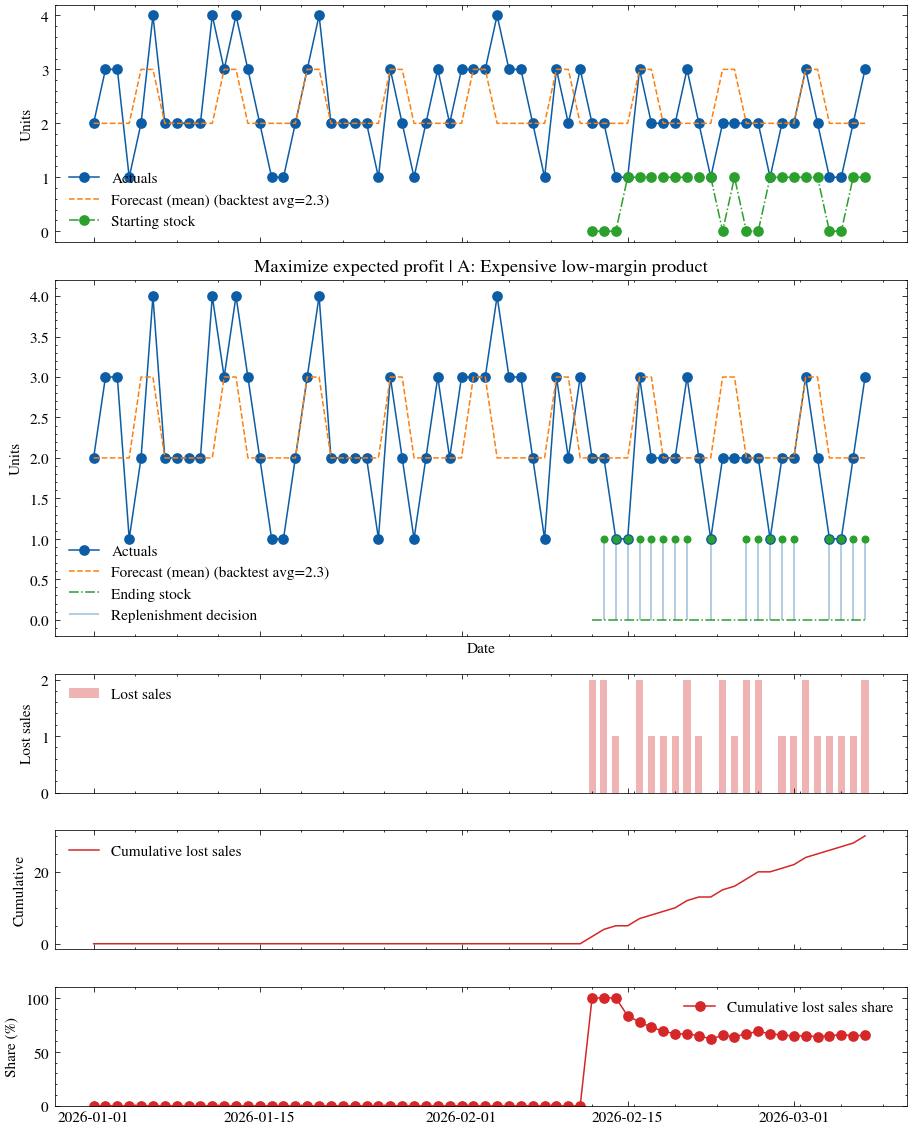

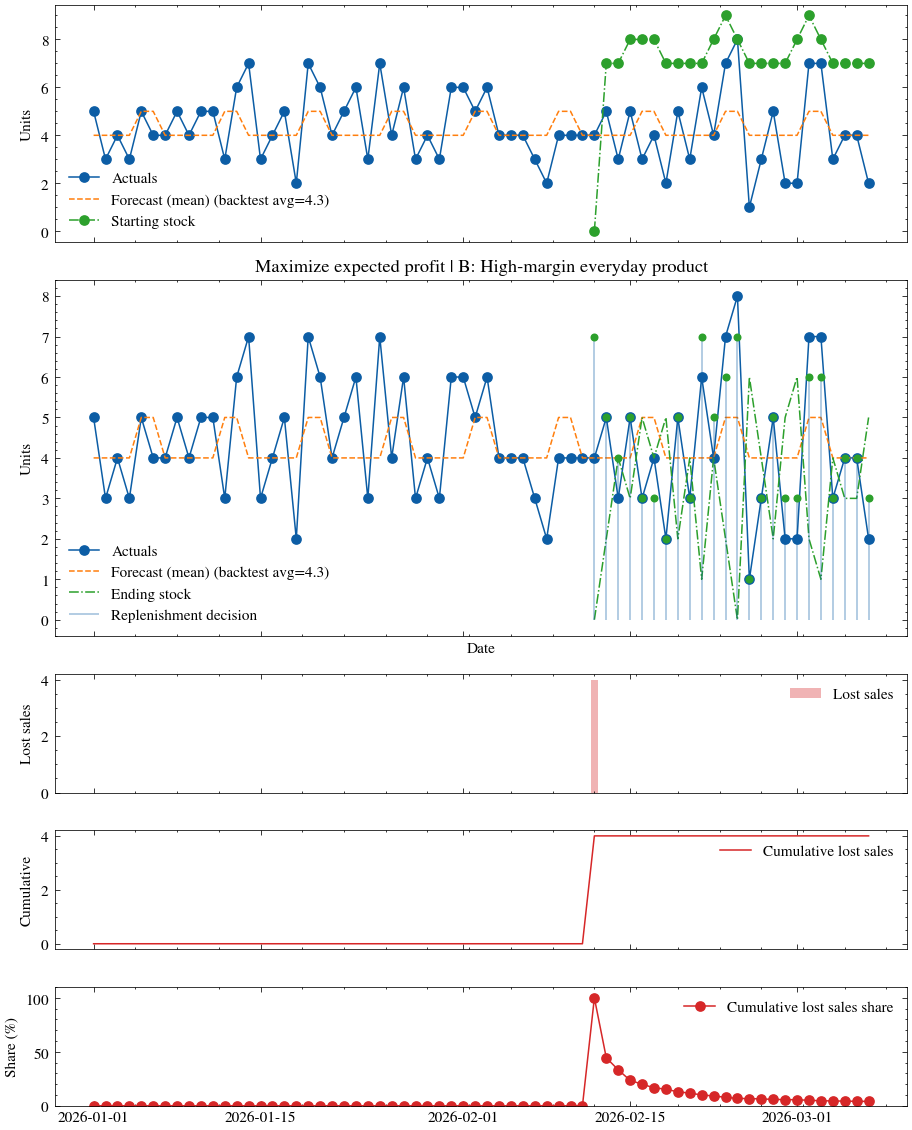

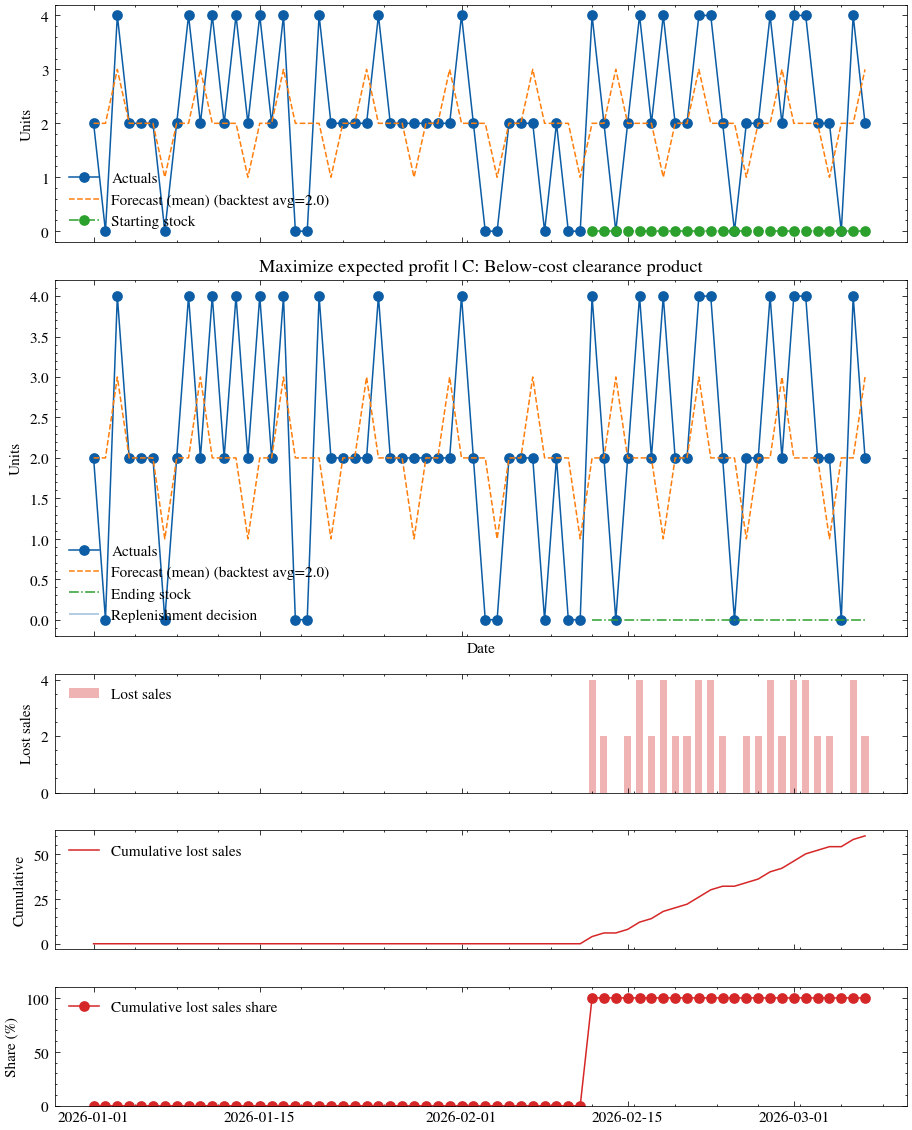

In [10]:
example_ids=sorted(decision_df["unique_id"].unique())[:3]
for uid in example_ids:
    ax=plot_replenishment_decisions(df,decision_df,unique_id=uid,
        title=f"{TITLE} | {uid}: {item_parameters[uid]['item']}",decision_style="line")
    figure=ax.figure
    path=PLOT_DIR/f"{METHOD}_standard_{uid}.png"
    figure.savefig(path,dpi=110,bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close(figure)


## 9. Overall demand and stock situation


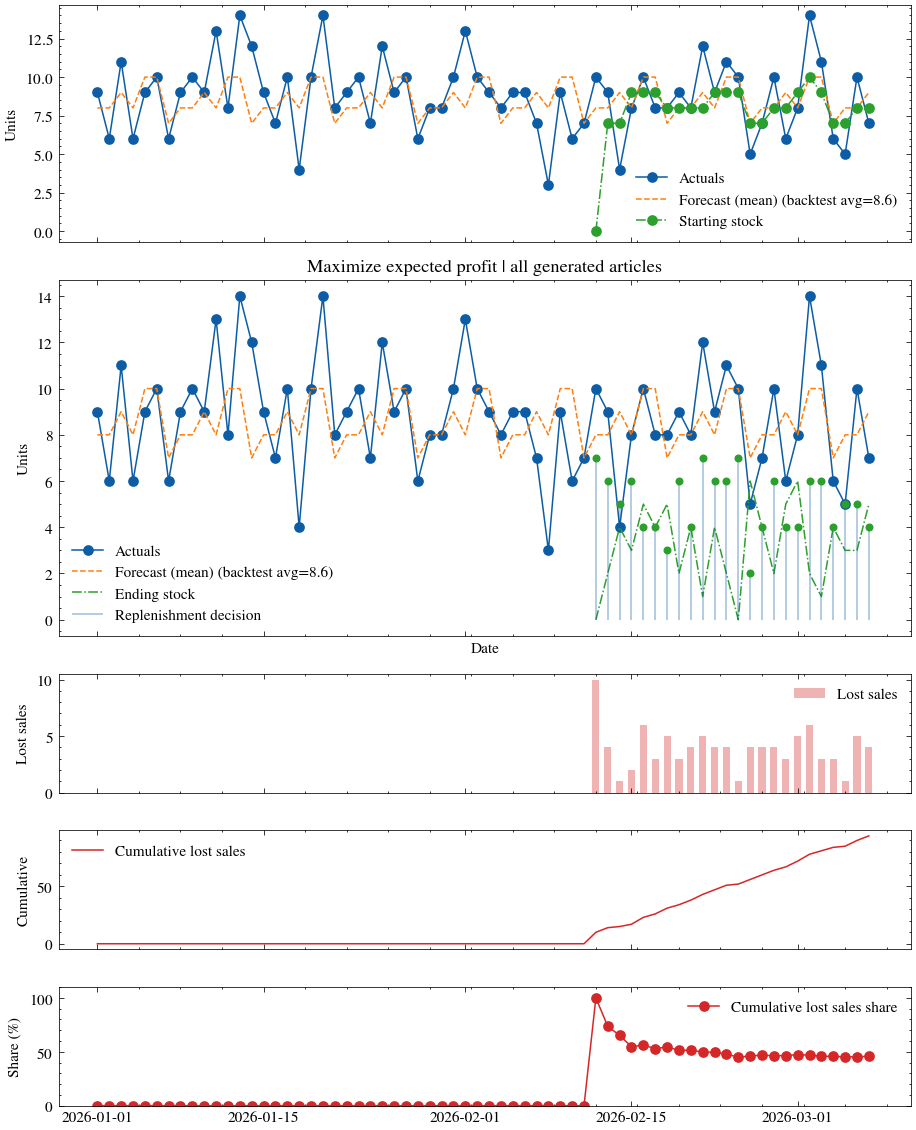

,articles,evaluation_periods,total_demand,fulfilled_units,missed_units,fill_rate,average_total_stock,peak_total_stock,ending_total_stock,ending_pipeline,total_cost
0,3,24,205,111,94,0.5415,3.2083,6,5,5,1515.4


,ds,demand,quantity,incoming_stock,starting_stock,ending_stock,on_order,missed_sales,fulfilled_units
0,2026-02-12,10,7,0,0,0,7,10,0
1,2026-02-13,9,6,7,7,2,6,4,5
2,2026-02-14,4,5,5,7,4,6,1,3
3,2026-02-15,8,6,5,9,3,7,2,6
4,2026-02-16,10,4,6,9,5,5,6,4
5,2026-02-17,8,4,4,9,4,5,3,5
6,2026-02-18,8,3,4,8,5,4,5,3
7,2026-02-19,9,6,3,8,2,7,3,6
8,2026-02-20,8,4,6,8,4,5,4,4
9,2026-02-21,12,7,4,8,1,8,5,7


In [11]:
# Aggregate jointly planned item trajectories; each item has its own stock.
ax=plot_replenishment_decisions(df,decision_df,aggregate=True,
    title=f"{TITLE} | all generated articles",decision_style="line")
figure=ax.figure
# Reconcile plotted cumulative missed sales with the actual simulation totals.
cumulative_line=next(line for axis in figure.axes for line in axis.lines
                     if line.get_label()=="Cumulative lost sales")
share_line=next(line for axis in figure.axes for line in axis.lines
               if line.get_label()=="Cumulative lost sales share")
total_demand=sum(result.summary.total_demand for result in eval_simulations.values())
total_missed=sum(result.summary.total_lost_sales for result in eval_simulations.values())
assert abs(float(cumulative_line.get_ydata()[-1])-total_missed)<1e-9
assert abs(float(share_line.get_ydata()[-1])-(100*total_missed/total_demand if total_demand else 0))<1e-9
path=PLOT_DIR/f"{METHOD}_standard_aggregate.png"
figure.savefig(path,dpi=110,bbox_inches="tight")
display(Image(filename=str(path)))
plt.close(figure)

overall_daily=decision_df.groupby("ds",as_index=False)[
    ["demand","quantity","incoming_stock","starting_stock","ending_stock","on_order","missed_sales"]
].sum()
overall_daily["fulfilled_units"]=overall_daily.demand-overall_daily.missed_sales
overall_summary_df=pd.DataFrame([dict(articles=len(eval_simulations),evaluation_periods=len(overall_daily),
    total_demand=total_demand,fulfilled_units=total_demand-total_missed,missed_units=total_missed,
    fill_rate=(1-total_missed/total_demand if total_demand else 1),
    average_total_stock=overall_daily.ending_stock.mean(),peak_total_stock=overall_daily.ending_stock.max(),
    ending_total_stock=overall_daily.ending_stock.iloc[-1],ending_pipeline=overall_daily.on_order.iloc[-1],
    total_cost=sum(result.summary.total_cost for result in eval_simulations.values()))])
display(overall_summary_df.round(4))
display(overall_daily.head(12))


## 10. Realized revenue, profit and purchasing comparison


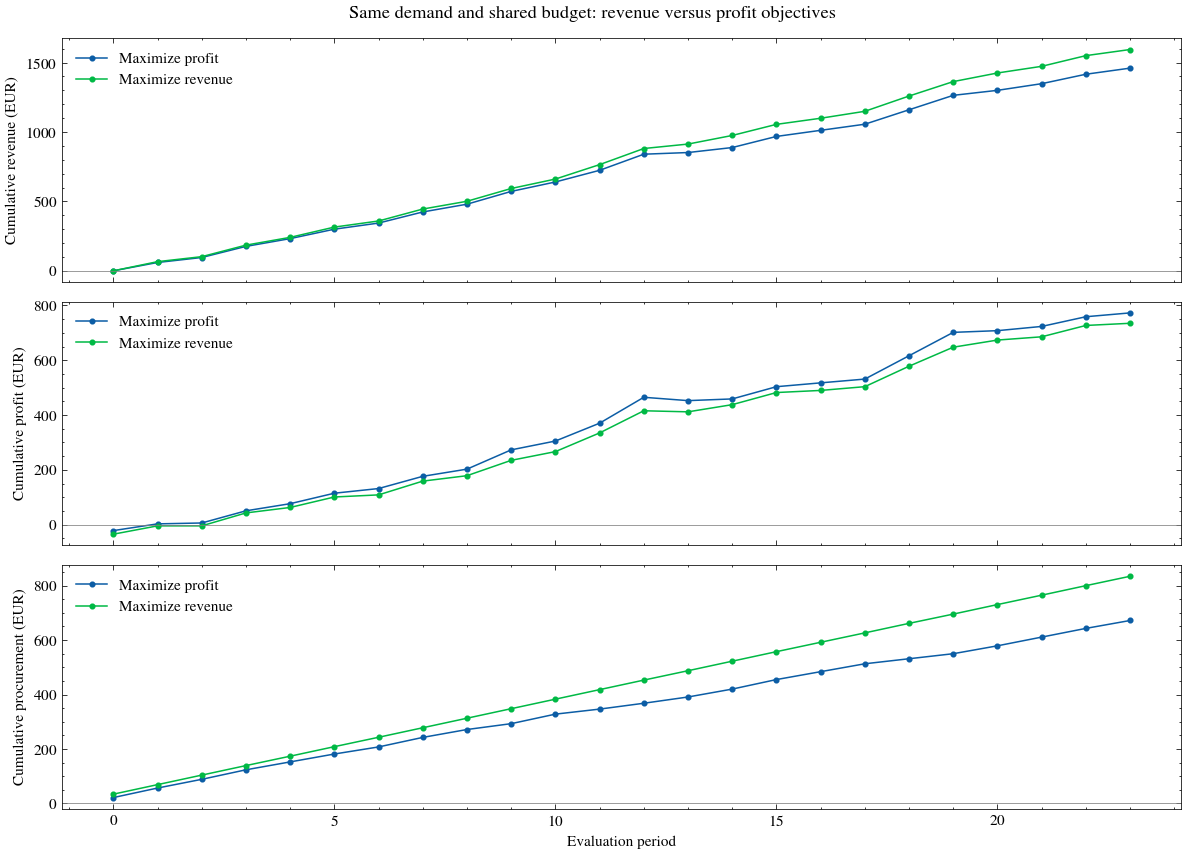

In [12]:
financial_daily = financial_df.groupby(["strategy","period"],as_index=False)[
    ["revenue","procurement_cost","holding_cost","profit"]].sum()
figure,axes = plt.subplots(3,1,figsize=(11,8),sharex=True)
for name,group in financial_daily.groupby("strategy"):
    for ax,column in zip(axes,["revenue","profit","procurement_cost"]):
        ax.plot(group.period,group[column].cumsum(),marker=".",label=name)
for ax,label in zip(axes,["Cumulative revenue (EUR)","Cumulative profit (EUR)","Cumulative procurement (EUR)"]):
    ax.set_ylabel(label);ax.legend(loc="best");ax.axhline(0,color="grey",linewidth=.5)
axes[-1].set_xlabel("Evaluation period")
figure.suptitle("Same demand and shared budget: revenue versus profit objectives")
figure.tight_layout()
path = PLOT_DIR/f"{METHOD}_financial_comparison.png"
figure.savefig(path,dpi=110,bbox_inches="tight")
display(Image(filename=str(path)))
plt.close(figure)


## 11. Shared budget and capacity utilization


,period,order_units,procurement_cost,receiving_units,received_before_order
0,0,7,21.5,0,0
1,1,6,35.0,7,7
2,2,5,32.0,5,5
3,3,6,35.0,5,5
4,4,4,29.0,6,6
5,5,4,29.0,4,4
6,6,3,26.0,4,4
7,7,6,35.0,3,3
8,8,4,29.0,6,6
9,9,7,21.5,4,4


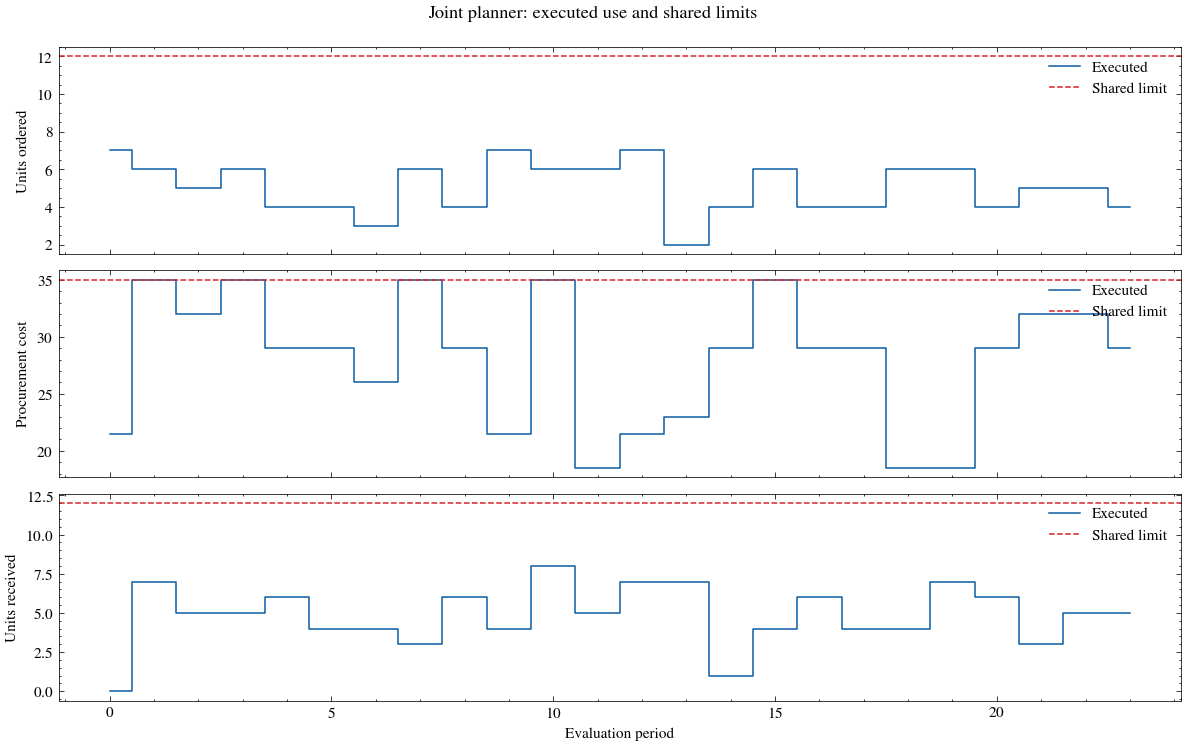

In [13]:
resource_df = pd.DataFrame([asdict(use) for use in coordinated.resource_use])
resource_df["received_before_order"] = [sum(result.snapshots[t].received
    for result in eval_simulations.values()) for t in range(len(resource_df))]
for t,use in enumerate(coordinated.resource_use):
    assert use.order_units == sum(result.snapshots[t].order_placed for result in eval_simulations.values())
    assert use.receiving_units == sum(result.snapshots[t].received + (
        result.snapshots[t].order_placed if items[uid].lead_time == 0 else 0)
        for uid,result in eval_simulations.items())
    assert use.order_units <= limits.max_order_units+1e-9
    assert use.procurement_cost <= limits.procurement_budget+1e-9
    assert use.receiving_units <= limits.max_receiving_units+1e-9
assert abs(resource_df.procurement_cost.sum()-sum(r.summary.ordering_cost for r in eval_simulations.values())) < 1e-7
display(resource_df.head(12))
figure,axes = plt.subplots(3,1,figsize=(11,7),sharex=True)
for ax,column,cap,label in zip(axes,["order_units","procurement_cost","receiving_units"],
    [limits.max_order_units,limits.procurement_budget,limits.max_receiving_units],
    ["Units ordered","Procurement cost","Units received"]):
    ax.step(resource_df.period,resource_df[column],where="mid",label="Executed")
    ax.axhline(cap,color="tab:red",linestyle="--",label="Shared limit")
    ax.set_ylabel(label); ax.legend(loc="upper right")
axes[-1].set_xlabel("Evaluation period")
figure.suptitle("Joint planner: executed use and shared limits")
figure.tight_layout()
path = PLOT_DIR/f"{METHOD}_shared_resources.png"
figure.savefig(path,dpi=110,bbox_inches="tight")
display(Image(filename=str(path)))
plt.close(figure)


## Interpretation and limits

The inspected horizon optimizes expected revenue/profit over supplied scenarios;
held-out realized results can differ. The finite model has zero terminal value,
no salvage or post-horizon fulfillment. The rolling policy is not told when the
evaluation ends, so its final purchases are charged even if they arrive later.
No warmup is removed. Prices are fixed and true demand is observed.

The EUR 35 limit resets each day. It is not a cash balance: sales do not finance
later orders, unused budget does not carry forward, and no accounts receivable,
taxes, financing, expiry or price-dependent demand are modeled. Profit here is
the defined inventory operating contribution, not a full accounting net profit.

Compare financial outcomes as well as service: a revenue optimizer may buy a
below-cost item, while a profit optimizer can deliberately leave its demand
unfulfilled. More sales need not mean more profit. See the
[solver guide](../docs/solver_policies.md).
